In [9]:
import requests
import json
import matplotlib.pyplot as plt

In [10]:
# 동영상 ID
video_id = "j_V6PTcCQCc"

get url!!!
get url finished!!!!!


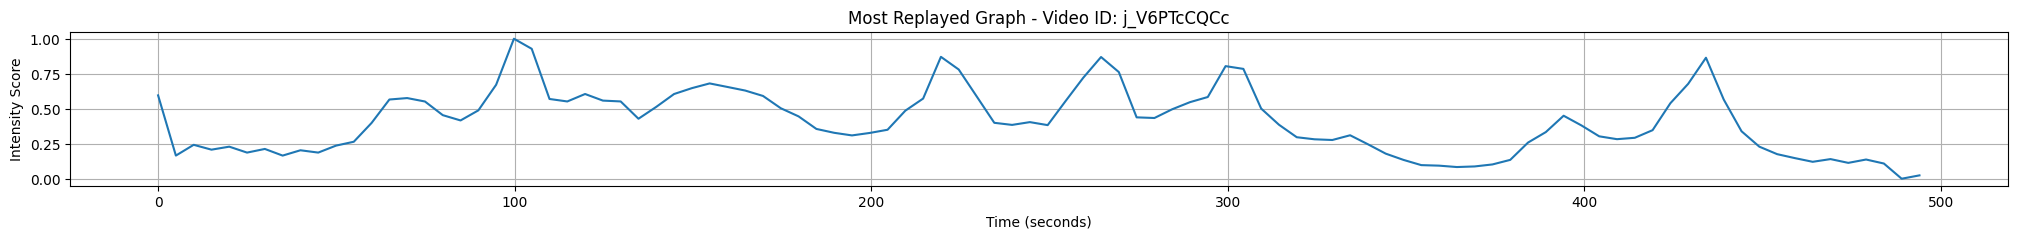

In [11]:
import requests
import json
import matplotlib.pyplot as plt



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


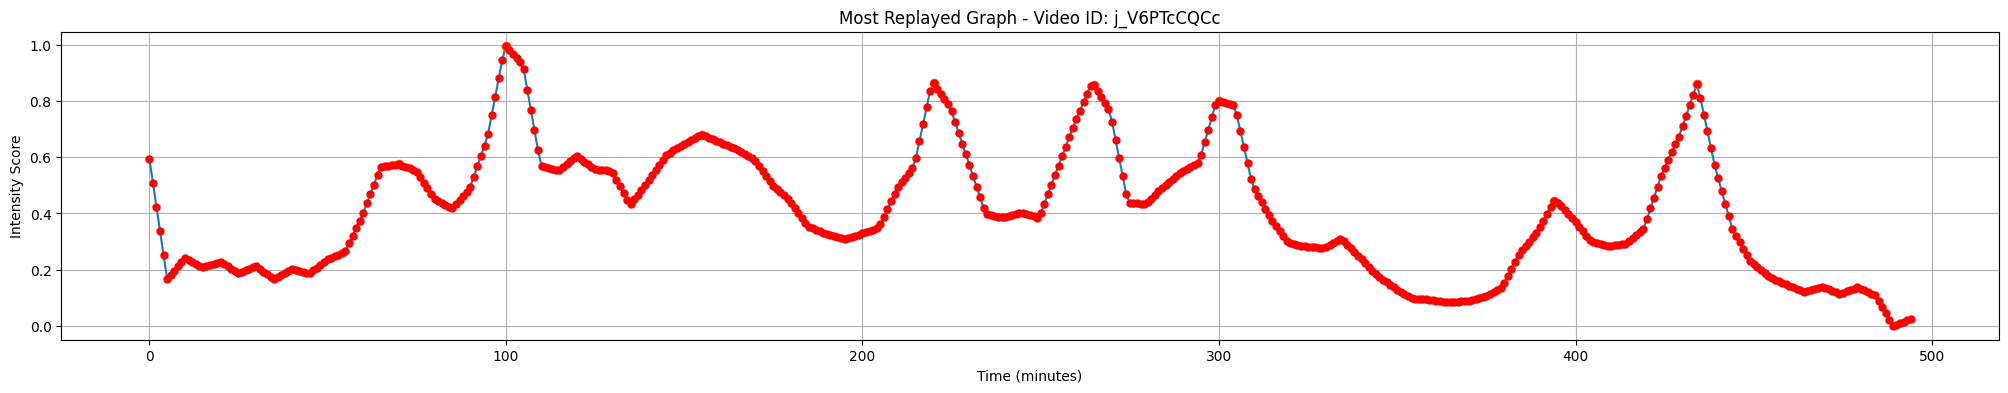

In [12]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')
plt.scatter(new_time, smoothed_intensity_scores, color='r', label='Selected Points', s=25, zorder=5)

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [13]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [14]:
scores = smoothed_intensity_scores

In [15]:
total_time = 30

In [16]:
max_t = total_time

In [17]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [18]:
len(states)

495

In [19]:
min_time = 4

In [20]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [21]:
set_next_states(states, min_time, max_t)

In [22]:
states[0][0].next_states

[(1, 1)]

In [40]:
def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace

def find_path(states, dp, trace, num_points=30, min_time=4):

    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if t >= min_time:
                if dp[i, t, num_points] > max_score:
                    max_score = dp[i, t, num_points]
                    max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        print(k, max_index)
        k -= 1
    
    selected_points.reverse()

    return selected_points, max_score

In [41]:
dp, trace = DP(states, num_points=total_time) 
selected_points, max_score = find_path(states, dp, trace, total_time, min_time)


30 (435, 3, 436, 4)
29 (434, 2, 435, 3)
28 (433, 1, 434, 2)
27 (432, 0, 433, 1)
26 (303, 4, 432, 0)
25 (302, 3, 303, 4)
24 (301, 2, 302, 3)
23 (300, 1, 301, 2)
22 (299, 0, 300, 1)
21 (267, 4, 299, 0)
20 (266, 3, 267, 4)
19 (265, 2, 266, 3)
18 (264, 1, 265, 2)
17 (263, 0, 264, 1)
16 (223, 4, 263, 0)
15 (222, 3, 223, 4)
14 (221, 2, 222, 3)
13 (220, 1, 221, 2)
12 (219, 0, 220, 1)
11 (106, 10, 219, 0)
10 (105, 9, 106, 10)
9 (104, 8, 105, 9)
8 (103, 7, 104, 8)
7 (102, 6, 103, 7)
6 (101, 5, 102, 6)
5 (100, 4, 101, 5)
4 (99, 3, 100, 4)
3 (98, 2, 99, 3)
2 (97, 1, 98, 2)
1 (96, 0, 97, 1)


In [42]:
max_score

25.608915825558782

In [38]:
selected_points

[96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 219,
 220,
 221,
 222,
 223,
 263,
 264,
 265,
 266,
 267,
 299,
 300,
 301,
 302,
 303,
 432,
 433,
 434,
 435]

In [28]:
selected_points

[97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 219,
 220,
 221,
 222,
 223,
 262,
 263,
 264,
 265,
 266,
 267,
 299,
 300,
 301,
 302,
 303,
 432,
 433,
 434,
 435]

In [29]:
max_score

25.65275575589446

In [43]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [44]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [45]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [46]:
# for group in grouped_points:
#     group.append(group[-1]+1)

In [47]:
grouped_points

[[96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106],
 [219, 220, 221, 222, 223],
 [263, 264, 265, 266, 267],
 [299, 300, 301, 302, 303],
 [432, 433, 434, 435]]

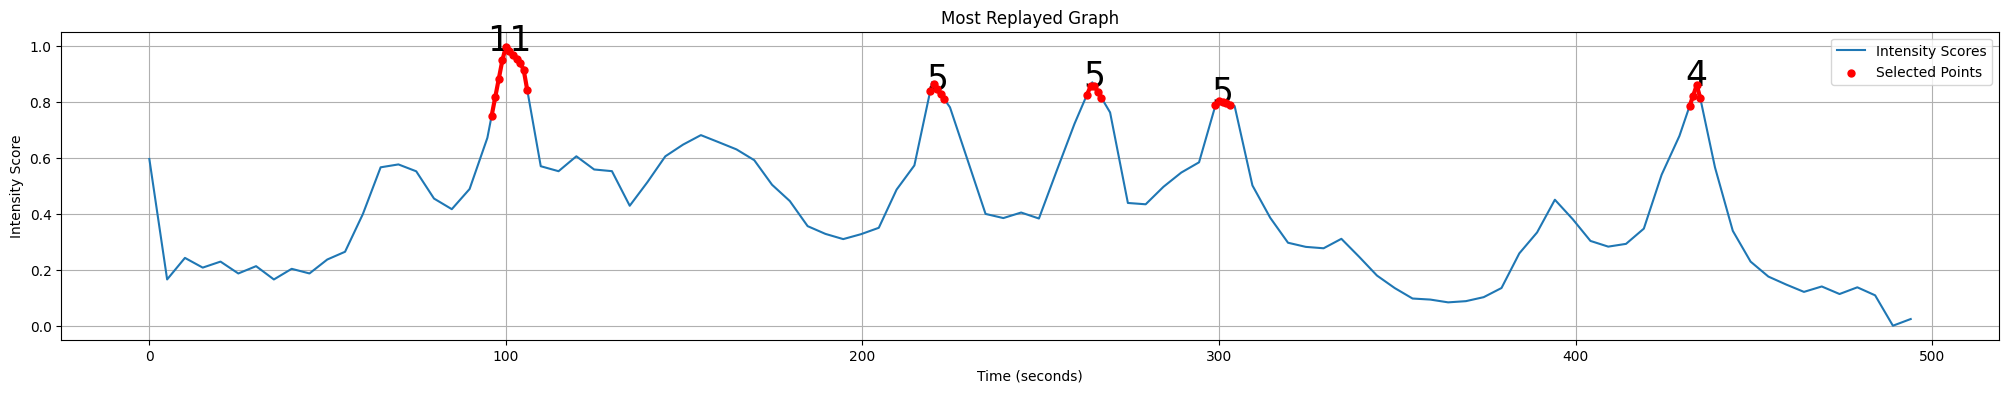

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# 가정: smoothed_intensity_scores와 start_seconds가 이미 정의되어 있음
# intervals = [(1, 7), (32, 38), (86, 114), (141, 146), (157, 162), (202, 208)]
plt.figure(figsize=(25, 4))
plt.plot(start_seconds, intensity_scores, label='Intensity Scores')
plt.scatter(selected_points, selected_smoothed_scores, color='r', label='Selected Points', s=25, zorder=5)

# 연속된 점들의 그룹 크기를 그래프에 표시
for group, size in zip(grouped_points, group_sizes):
    mid_point = group[len(group) // 2]
    plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=25, ha='center')

for group in grouped_points:
    for i in range(len(group) -1 ):
        plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=3)


plt.title('Most Replayed Graph')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
threshold_intervals

[(97, 107), (219, 225), (262, 269), (300, 304), (433, 436)]

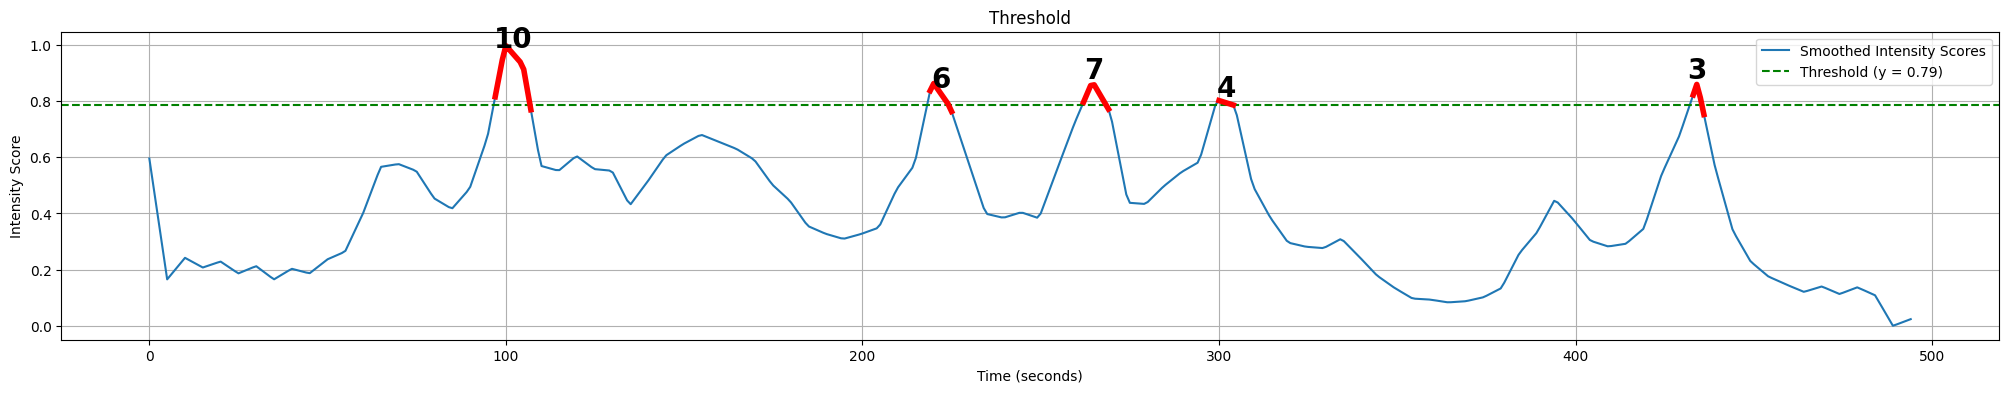

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 가정: smoothed_intensity_scores와 start_seconds가 이미 정의되어 있음
# intervals = [(1, 7), (32, 38), (86, 114), (141, 146), (157, 162), (202, 208)]

plt.figure(figsize=(25, 4))


# 원래 그래프 그리기
plt.plot(new_time, smoothed_intensity_scores, label='Smoothed Intensity Scores')
plt.axhline(y=threshold, color='green', linestyle='--', label='Threshold (y = {:.2f})'.format(threshold))

# intervals 표시
for start, end in threshold_intervals:
    # start_seconds가 0부터 시작한다고 가정
    plt.plot(new_time[start:end+1], smoothed_intensity_scores[start:end+1], color='red', linewidth=4)
    # 점 개수 계산
    point_count = end - start 
    
    # 그룹의 중간 위치 계산
    mid_point = (start + end) // 2
    
    # 점 개수 텍스트 표시
    plt.text(new_time[mid_point], smoothed_intensity_scores[mid_point], 
             str(point_count), color='black', fontweight='bold', fontsize=20,
             ha='center', va='bottom')

plt.title('Threshold')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
def knapSack(W, wt, val, n):
    K = [[0 for x in range(W + 1)] for x in range(n + 1)]
    for i in range(n + 1):
        for w in range(W + 1):
            if i == 0 or w == 0:
                K[i][w] = 0
            elif wt[i-1] <= w:
                K[i][w] = max(val[i-1] + K[i-1][w-wt[i-1]], K[i-1][w])
            else:
                K[i][w] = K[i-1][w]
    
    res, w = K[n][W], W
    picks = []
    for i in range(n, 0, -1):
        if res <= 0:
            break
        if res != K[i-1][w]:
            picks.append(i-1)
            res, w = res - val[i-1], w - wt[i-1]
    return picks

def generate_summary(smoothed_intensity_scores, new_time, segment_length, time):
    n_frames = len(smoothed_intensity_scores)
    segment_frames = int(segment_length * (n_frames / new_time[-1]))
    n_segments = n_frames // segment_frames
    segments = np.array_split(smoothed_intensity_scores, n_segments)
    
    segment_scores = [segment.mean() for segment in segments]
    segment_lengths = [len(segment) for segment in segments]
    picks = knapSack(time, segment_lengths, segment_scores, n_segments)
    
    selected_intervals = []
    for pick in sorted(picks):
        start = pick * segment_frames
        end = min((pick + 1) * segment_frames, n_frames)
        selected_intervals.append((new_time[start], new_time[end - 1]))
    
    return merge_intervals(selected_intervals)

def merge_intervals(intervals):
    if not intervals:
        return []
    
    sorted_intervals = sorted(intervals, key=lambda x: x[0])
    merged = []
    for interval in sorted_intervals:
        if not merged or interval[0] > merged[-1][1] + 1:
            merged.append(interval)
        else:
            merged[-1] = (merged[-1][0], max(merged[-1][1], interval[1]))
    
    return merged

Selected intervals: [(228.0, 266.0), (300.0, 302.0), (432.0, 434.0)]


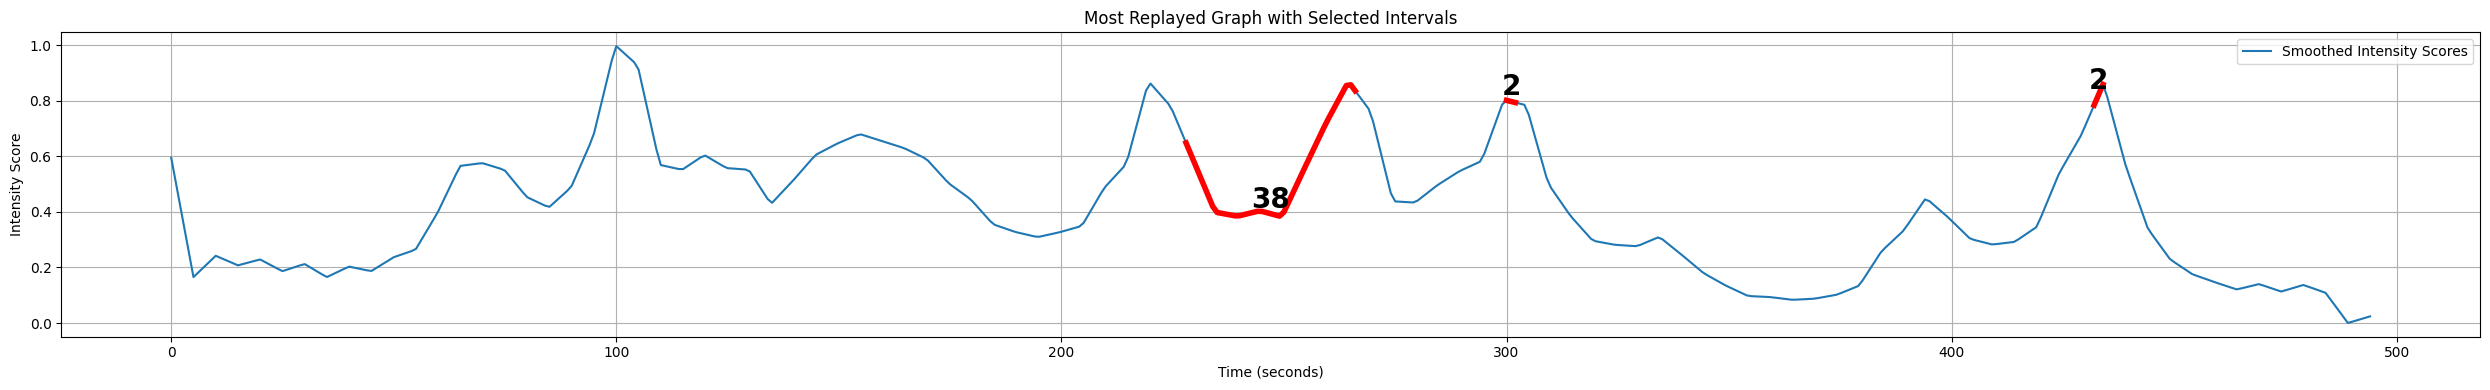

In [ ]:
# 사용 예시
segment_length= 3
knapsack_intervals = generate_summary(smoothed_intensity_scores, new_time, segment_length, time=total_time)
merged_intervals = merge_intervals(knapsack_intervals)

print("Selected intervals:", merged_intervals)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores, label='Smoothed Intensity Scores')

for start, end in merged_intervals:
    # start_seconds가 0부터 시작한다고 가정
    start = int(start)
    end = int(end)
    plt.plot(new_time[start:end+1], smoothed_intensity_scores[start:end+1], color='red', linewidth=4)
    # 점 개수 계산
    point_count = end - start 
    
    # 그룹의 중간 위치 계산
    mid_point = (start + end) // 2
    
    # 점 개수 텍스트 표시
    plt.text(new_time[mid_point], smoothed_intensity_scores[mid_point], 
             str(point_count), color='black', fontweight='bold', fontsize=20,
             ha='center', va='bottom')

plt.title('Most Replayed Graph with Selected Intervals')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()